# WP09 — Son kapanış denetimi

Kullanıcı gerçek protein-PPI eğitimini araştırma kapsamında kabul etti. Bu notebook yeni kapanış kanıtlarını gösterir; mevcut model/OOF skorlarını değiştirmez. Yeniden çalıştırılan 24 testin kontrollü RAM fitleri deney sonuçlarını ezmez. Aşağıdaki hücreler yalnız kayıtlı QA okur; optimizer veya fit yoktur.

Üç ayrı sonuç: **(1)** PPI gerçekten hesaplanıyor/öğreniliyor: teknik kanıt var. **(2)** Ek birincil tahmin katkısı: bu deneyde gösterilmedi. **(3)** Protein biyolojisi genel olarak yararsızdır: bu çıkarım yapılamaz.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

C=ROOT/'reports/qa/WP09/final_closure_v1';T=ROOT/'reports/qa/WP09/training_v1'
F=ROOT/'reports/figures/WP09/final_closure_v1';F.mkdir(parents=True,exist_ok=True)
checks=json.loads((C/'closure_checks.json').read_text(encoding='utf-8'))
display(pd.DataFrame([checks]).T.rename(columns={0:'doğrulanmış_sonuç'}))


,doğrulanmış_sonuç
status,PASS
previous_artifacts_preserved,2347
model_NPZ,190
model_metadata_JSON,190
numeric_states_rehashed,190
real_trainer_tests_rerun,24
test_seconds,22.927
outer_models_restored,5
max_score_reconstruction_error,0.0
trained_forward_backward_probes,5


**Yorum:** 190 NPZ ve190 metadata dosyasının hash'i,190 sayısal state ve2347 önceki dosya doğrulandı. Kaynak62/1061/6416 değişmedi. Test logu ayrı dosyadadır; eski log korunur. Büyük ham dosyalar tekrar taranmadı.

## 1. Kaydedilmiş ağırlıklardan gerçek skor üretimi

In [2]:

display(pd.read_csv(C/'NPZ_score_reconstruction.csv'))
display(pd.read_csv(C/'same_key_checks.csv'))


,context,model,pairs,max_absolute_error,NPZ_restored
0,primary_o01_final,G_noPPI,3120,1.110223e-16,True
1,primary_o01_final,G_realPPI,3120,1.110223e-16,True
2,primary_o01_final,G_shuffledPPI_R0,3120,1.110223e-16,True
3,primary_o01_final,G_shuffledPPI_R1,3120,1.110223e-16,True
4,primary_o01_final,G_shuffledPPI_R2,3120,1.110223e-16,True


,protocol,model,key_count,same_keys
0,primary,G_noPPI,18004,True
1,primary,G_realPPI,18004,True
2,primary,G_shuffledPPI_R0,18004,True
3,primary,G_shuffledPPI_R1,18004,True
4,primary,G_shuffledPPI_R2,18004,True
5,stress,G_noPPI,17970,True
6,stress,G_realPPI,17970,True
7,stress,G_shuffledPPI_R0,17970,True
8,stress,G_shuffledPPI_R1,17970,True
9,stress,G_shuffledPPI_R2,17970,True


**Yorum:** Primary outer1'in no/real/R0/R1/R2 ağırlıkları NPZ'den yüklenip yalnız test query girdileriyle çalıştırıldı. En büyük sayısal fark yaklaşık1,1×10⁻¹⁶;float32 skorların CSV float yazım/okuma yuvarlaması sınırındadır. Bütün modeller ana/stres için aynı drug/fold/PT anahtarlarını taşır. Bu yeni değerlendirme veya model seçimi değildir.

## 2. Eğitilmiş ağırlıklarda edge etkisi ve gradient

,context,model,same_weights_PPI_removed_protein_L2,trained_message_weight_gradient_norm,train_BCE_at_saved_weights,optimizer_steps_this_check,state_unchanged
0,primary_o01_final,G_noPPI,0.000000,0.000000,0.478758,0,True
1,primary_o01_final,G_realPPI,13.162168,0.004016,0.469810,0,True
2,primary_o01_final,G_shuffledPPI_R0,11.759402,0.007910,0.480233,0,True
3,primary_o01_final,G_shuffledPPI_R1,11.306178,0.002783,0.461517,0,True
4,primary_o01_final,G_shuffledPPI_R2,12.112257,0.005754,0.475528,0,True


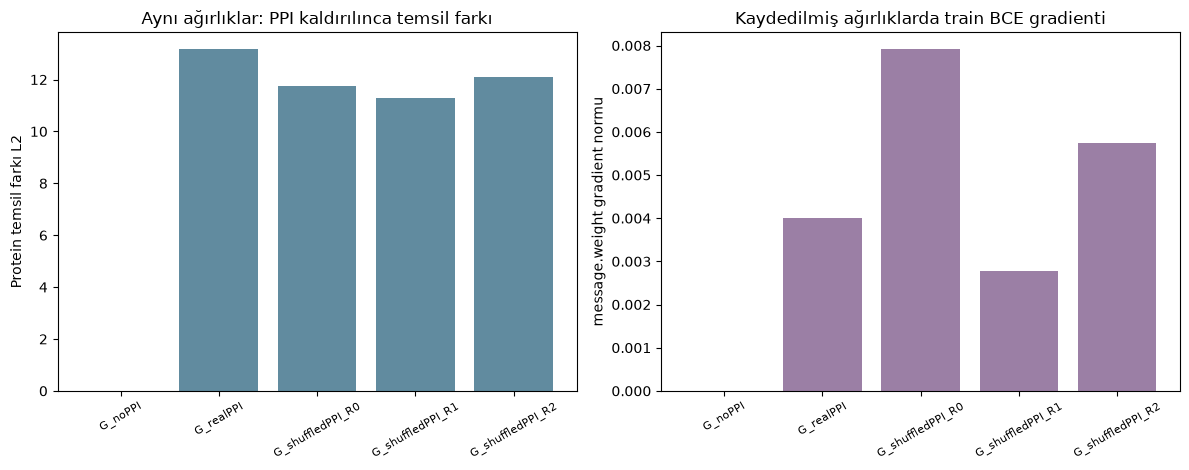

In [3]:

proof=pd.read_csv(C/'trained_forward_gradient.csv');display(proof)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
axs[0].bar(proof.model,proof.same_weights_PPI_removed_protein_L2,color='#618b9f')
axs[1].bar(proof.model,proof.trained_message_weight_gradient_norm,color='#9b7fa5')
axs[0].set(title='Aynı ağırlıklar: PPI kaldırılınca temsil farkı',ylabel='Protein temsil farkı L2')
axs[1].set(title='Kaydedilmiş ağırlıklarda train BCE gradienti',ylabel='message.weight gradient normu')
for ax in axs:ax.tick_params(axis='x',labelrotation=30,labelsize=8)
plt.tight_layout();plt.savefig(F/'01_trained_edge_gradient_check.png',dpi=160);plt.show()


**Yorum:** Aynı eğitilmiş real ağırlıklarda kenarları kaldırmak protein temsillerini değiştiriyor. Train-only BCE backward mesaj katmanına gradient ulaştırıyor. NoPPI'da komşu etkisi/gradient0. Probe optimizer adımı0 ve state hash'i aynı;bu bir yeniden eğitim değildir. Bu kontrol, önceki gerçek optimizer/gradient kayıtlarıyla birlikte teknik kullanım ve öğrenmeyi destekler;etkinlik üstünlüğünü göstermez.

## 3. Değişmeyen bilimsel sonuç

,estimate,CI95_low,CI95_high
model,,,
G_noPPI,0.643021,0.598498,0.684101
G_realPPI,0.642880,0.597754,0.684922
G_shuffledPPI_mean3_metrics,0.643259,0.597924,0.685026


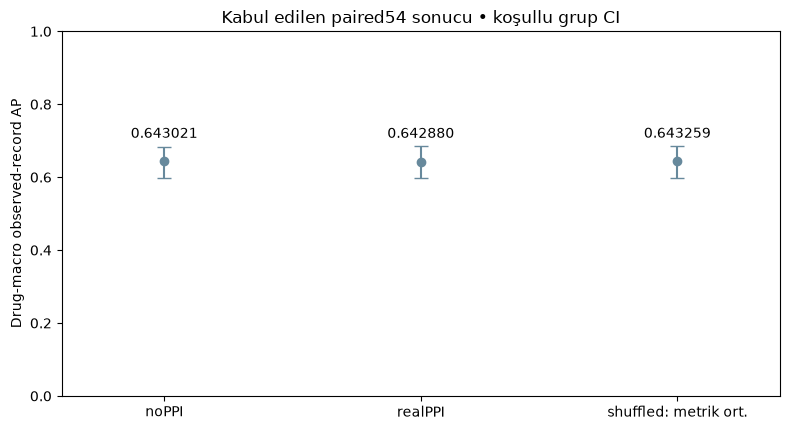

,first,reference,first_minus_reference,CI95_low,CI95_high
0,G_realPPI,G_noPPI,-0.000142,-0.003611,0.003248
3,G_realPPI,G_shuffledPPI_mean3_metrics,-0.000379,-0.002039,0.001310
9,G_realPPI,B2,0.016641,-0.000899,0.034086
12,G_realPPI,B0_like_B2,-0.003724,-0.016303,0.007884
21,G_realPPI,B1,-0.012762,-0.031658,0.004782


In [4]:

m=pd.read_csv(T/'metrics_with_group_CI.csv')
order=['G_noPPI','G_realPPI','G_shuffledPPI_mean3_metrics']
a=m[m.protocol.eq('primary')&m.scope.eq('paired54')&m.metric.eq('drug_macro_AP')].set_index('model').loc[order]
display(a[['estimate','CI95_low','CI95_high']])
fig,ax=plt.subplots(figsize=(8,4.4))
ax.errorbar(range(3),a.estimate,yerr=np.vstack([a.estimate-a.CI95_low,a.CI95_high-a.estimate]),fmt='o',capsize=5,color='#67899c')
ax.set_xticks(range(3),['noPPI','realPPI','shuffled: metrik ort.']);ax.set(ylabel='Drug-macro observed-record AP',ylim=(0,1),xlim=(-.4,2.4),title='Kabul edilen paired54 sonucu • koşullu grup CI')
for i,val in enumerate(a.estimate):ax.text(i,val+.065,f'{val:.6f}',ha='center')
plt.tight_layout();plt.savefig(F/'02_frozen_primary_result.png',dpi=160);plt.show()
d=pd.read_csv(T/'paired_differences_group_CI.csv')
display(d[d.protocol.eq('primary')&d.scope.eq('paired54')&d.metric.eq('drug_macro_AP')&d['first'].eq('G_realPPI')][['first','reference','first_minus_reference','CI95_low','CI95_high']])


**Yorum:** Gerçek PPI'nin noPPI ve karıştırılmış ağlara ek drug-AP katkısı gösterilmedi. B1−GNN farkında kimya/protein girdisi,LR/nonlineer öğrenme,kapasite ve optimizasyon da değişir;tek başına PPI topolojisine atfedilemez. KoşulluCI sıfırı içermesi eşdeğerlik kanıtı değildir. Küçük kohort,rol-mean,insan PPI kapsamı ve SIDER kayıt yanlılığı protein biyolojisinin genel yararsızlığı sonucunu engeller.

## 4. Kapsam ve NA görünür kalır

In [5]:

coverage=pd.read_csv(T/'evaluation_coverage.csv')
display(coverage[coverage.model.eq('G_realPPI')])
status=pd.read_csv(T/'prediction_status_all62.csv');display(status.groupby(['protocol','model','status']).size().rename('ilaç').reset_index())
display(pd.read_csv(T/'excluded_inner_jobs.csv'))
display(pd.DataFrame([{'yeni_log':'trainer_tests_rerun.txt','test':24,'saniye':checks['test_seconds'],'durum':'OK','eski_log_ezildi':False}]))


,protocol,scope,model,semantics,inventory_drugs,expected_comparison_drugs,scored_drugs,AP_evaluable_drugs,expected_scored_pairs,scored_pairs,excluded_comparison_keys,observed_positive_scored,unknown_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,scored_class_union,class_AUROC_evaluable,class_AUROC_NA
6,primary,paired54,G_realPPI,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...,62,54,54,54,13964,13964,0,3820,10144,5505,1685,306,256,50
14,primary,own61,G_realPPI,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...,62,61,61,61,18004,18004,0,4576,13428,6405,1829,350,293,57
24,stress,paired54,G_realPPI,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...,62,54,54,54,13890,13890,0,3751,10139,5505,1754,307,257,50
32,stress,own61,G_realPPI,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...,62,61,61,61,17970,17970,0,4569,13401,6405,1836,351,300,51


,protocol,model,status,ilaç
0,primary,G_noPPI,ABSTAIN_no_input,1
1,primary,G_noPPI,SCORED,61
2,primary,G_realPPI,ABSTAIN_no_input,1
3,primary,G_realPPI,SCORED,61
4,primary,G_shuffledPPI_R0,ABSTAIN_no_input,1
5,primary,G_shuffledPPI_R0,SCORED,61
6,primary,G_shuffledPPI_R1,ABSTAIN_no_input,1
7,primary,G_shuffledPPI_R1,SCORED,61
8,primary,G_shuffledPPI_R2,ABSTAIN_no_input,1
9,primary,G_shuffledPPI_R2,SCORED,61


,context,protocol,outer_fold,inner_fold,model,status,failed_null_replicas,optimizer_steps,prediction_produced
0,primary_o02_i01,primary,2,1,G_noPPI,SKIPPED_SHARED_NULL_FAILURE,2,0,False
1,primary_o02_i01,primary,2,1,G_realPPI,SKIPPED_SHARED_NULL_FAILURE,2,0,False
2,primary_o02_i01,primary,2,1,G_shuffledPPI_R0,SKIPPED_SHARED_NULL_FAILURE,2,0,False
3,primary_o02_i01,primary,2,1,G_shuffledPPI_R1,SKIPPED_SHARED_NULL_FAILURE,2,0,False
4,primary_o02_i01,primary,2,1,G_shuffledPPI_R2,SKIPPED_SHARED_NULL_FAILURE,2,0,False
5,stress_o02_i02,stress,2,2,G_noPPI,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
6,stress_o02_i02,stress,2,2,G_realPPI,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
7,stress_o02_i02,stress,2,2,G_shuffledPPI_R0,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
8,stress_o02_i02,stress,2,2,G_shuffledPPI_R1,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
9,stress_o02_i02,stress,2,2,G_shuffledPPI_R2,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False


,yeni_log,test,saniye,durum,eski_log_ezildi
0,trainer_tests_rerun.txt,24,22.927,OK,False


**Yorum:** Primary paired54'te1685 kaynak pozitif hedef/fit kapsamı dışında;bu bütün62'nin yanlış-negatif sayısı değildir.61 ilaç skorlanır,Methenamine abstain. Üç null NA,iki shared-excluded inner bağlam/10 iş ve tek-proxy sınıflar görünür kalır. Unknown gerçek biyolojik negatif değildir. Skorlar klinik risk,kalibrasyon,nedensellik veya hasta güvenliği doğrulaması değildir. WP09 kapanır;WP10 yalnız ayrı tasarım/uygulanabilirlik incelemesidir.